# Soft-constrained MPC with OSQP slack penalties

A soft QP adds a slack $\xi$ to the constraints and a penalty $\Phi(\xi)$ to the cost:

$$
\min_{z,\,\xi}\ \tfrac12 z^\top P z + q^\top z + \Phi(\xi)
\quad\text{s.t.}\quad l \le A z + \xi \le u .
$$

Our modified OSQP implementation eliminates $\xi$ internally, so the soft QP has the same size as the hard one. Each constraint row $i$ gets one `PenaltyType`:

| `PenaltyType` | Penalty |
|---|---|
| `OSQP_PENALTY_NONE` | $\xi_i = 0$ (hard constraint) |
| `OSQP_PENALTY_L1L2` | $\phi(\xi_i) = \alpha_1 \lvert\xi_i\rvert + \tfrac{\alpha_2}{2}\xi_i^2$ |
| `OSQP_PENALTY_HUBER` | $\phi(\xi_i) = \alpha_1 h_\delta(\xi_i)$, with $h_\delta(s) = \begin{cases} \tfrac12 s^2 & \lvert s\rvert \le \delta \\ \delta(\lvert s\rvert - \tfrac{\delta}{2}) & \text{otherwise} \end{cases}$ |
| `OSQP_PENALTY_NORM2` | $\Phi(\xi_G) = \alpha_1 \lVert\xi_G\rVert_2$ over a group $G$ of rows |
| `OSQP_PENALTY_NORMINF` | $\Phi(\xi_G) = \alpha_1 \lVert\xi_G\rVert_\infty$ over a group $G$ of rows |

`L1L2` covers the quadratic ($\alpha_1 = 0$), $\ell_1$ ($\alpha_2 = 0$), and elastic-net penalties.

This notebook uses a cart that must stay below a position limit, and shows:

1. hard constraints become infeasible after a disturbance, soft constraints recover;
2. quadratic vs. $\ell_1$ penalty;
3. updating the penalty online.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import osqp
from scipy import sparse

%config InlineBackend.figure_format = "retina"

PT = osqp.PenaltyType
for penalty_type in PT:
    print(penalty_type.name)

OSQP_PENALTY_NONE
OSQP_PENALTY_L1L2
OSQP_PENALTY_HUBER
OSQP_PENALTY_NORM2
OSQP_PENALTY_NORMINF


## The MPC problem

<img src="cart.png" width="445" alt="cart">

The cart has state $x = (p, v)$, position and velocity. The control input $u$ is its acceleration:

$$x_{k+1} = A_d x_k + B_d u_k, \qquad A_d = \begin{bmatrix}1 & \Delta t\\ 0 & 1\end{bmatrix}, \quad B_d = \begin{bmatrix}\Delta t^2/2\\ \Delta t\end{bmatrix}.$$

The MPC tracks $p_\mathrm{ref}$ over $N$ steps. The position limit $p_{\max}$ is soft (slack $\xi_k$), the input limit $u_{\max}$ is hard:

$$
\begin{aligned}
\min_{x,\, u,\, \xi}\quad & \sum_{k=0}^{N} \tfrac12 (x_k - x_\mathrm{ref})^\top Q (x_k - x_\mathrm{ref}) + \sum_{k=0}^{N-1} \tfrac12 R\, u_k^2 + \sum_{k=0}^{N} \phi(\xi_k) \\
\text{s.t.}\quad & x_0 = x_\mathrm{init},\quad x_{k+1} = A_d x_k + B_d u_k, \\
& -p_{\max} \le p_k + \xi_k \le p_{\max}, \\
& -u_{\max} \le u_k \le u_{\max}.
\end{aligned}
$$

We stack $z = (x_0, \dots, x_N, u_0, \dots, u_{N-1})$ to get the QP form above.

In [2]:
dt, N = 0.1, 20
Ad = np.array([[1.0, dt], [0.0, 1.0]])
Bd = np.array([[0.5 * dt**2], [dt]])
nx, nu = 2, 1
Q = np.diag([10.0, 0.1])
R = np.array([[0.1]])
p_max, u_max = 1.0, 1.0

# Cost: 1/2 z'Pz + q'z
P = sparse.block_diag([sparse.kron(sparse.eye(N + 1), Q), sparse.kron(sparse.eye(N), R)], format="csc")


def linear_cost(p_ref):
    x_ref = np.array([p_ref, 0.0])
    return np.concatenate([np.tile(-Q @ x_ref, N + 1), np.zeros(N * nu)])


# Constraints: dynamics (with the initial state), position, input
A_dyn = sparse.hstack(
    [
        sparse.kron(sparse.eye(N + 1), -sparse.eye(nx)) + sparse.kron(sparse.eye(N + 1, k=-1), Ad),
        sparse.kron(sparse.vstack([sparse.csc_matrix((1, N)), sparse.eye(N)]), Bd),
    ]
)
A_pos = sparse.hstack([sparse.kron(sparse.eye(N + 1), [[1.0, 0.0]]), sparse.csc_matrix((N + 1, N * nu))])
A_inp = sparse.hstack([sparse.csc_matrix((N * nu, (N + 1) * nx)), sparse.eye(N * nu)])
A = sparse.vstack([A_dyn, A_pos, A_inp], format="csc")
num_constraints = A.shape[0]

# Rows of the position constraints (the soft ones)
pos_rows = np.arange((N + 1) * nx, (N + 1) * nx + N + 1)


def bounds(x_init):
    dyn = np.concatenate([-x_init, np.zeros(N * nx)])
    lower = np.concatenate([dyn, np.full(N + 1, -p_max), np.full(N * nu, -u_max)])
    upper = np.concatenate([dyn, np.full(N + 1, p_max), np.full(N * nu, u_max)])
    return lower, upper


print(f"QP with {P.shape[0]} variables and {num_constraints} constraints")

QP with 62 variables and 83 constraints


## Controllers

A soft controller is a standard OSQP setup followed by one call to `setup_penalty`. Only the position rows get slack variables.

In [3]:
SETTINGS = dict(eps_abs=1e-5, eps_rel=1e-5, polishing=False, verbose=False)


def controller(penalty_type=None, alpha1=0.0, alpha2=0.0, delta=0.0, p_ref=0.9):
    # Standard OSQP setup (the initial state is set later, in simulate)
    solver = osqp.OSQP()
    lower, upper = bounds(np.zeros(nx))
    solver.setup(P, linear_cost(p_ref), A, lower, upper, **SETTINGS)

    # Vanilla OSQP: no penalty, all constraints stay hard
    if penalty_type is None:
        return solver

    # One penalty type per constraint row: all hard ...
    types = np.full(num_constraints, PT.OSQP_PENALTY_NONE)
    # ... except the position constraints, which get slack variables
    types[pos_rows] = penalty_type

    # Weights can be scalars or per-row arrays; hard rows ignore them
    solver.setup_penalty(types, alpha1=alpha1, alpha2=alpha2, delta=delta)
    return solver

## Closed-loop simulation

At each step, the current state enters the QP through the bounds, via `update(l=..., u=...)`. At $t = 2\,s$, a disturbance (`kick`) pushes the cart towards the limit.

In [4]:
def simulate(solver, steps=60, kick_step=20, kick=0.6):
    x = np.zeros(nx)
    states, inputs = [x], []
    for k in range(steps):
        # Disturbance: add velocity to the cart
        if k == kick_step:
            x = x + np.array([0.0, kick])

        # Set the current state as the initial state of the MPC
        lower, upper = bounds(x)
        solver.update(l=lower, u=upper)

        # Solve the MPC problem
        result = solver.solve(raise_error=False)
        if result.info.status != "solved":
            print(f"t = {k * dt:.1f} s: {result.info.status}, the controller fails")
            break

        # Apply the first input and step the cart forward
        u = result.x[(N + 1) * nx]
        x = Ad @ x + Bd[:, 0] * u
        states.append(x)
        inputs.append(u)
    return np.array(states), np.array(inputs)

### 1. Hard constraints fail, soft constraints recover

After the kick, the cart cannot stop before $p_{\max}$. The hard QP is infeasible. The soft controllers brake and return below the limit.

t = 2.0 s: primal infeasible, the controller fails


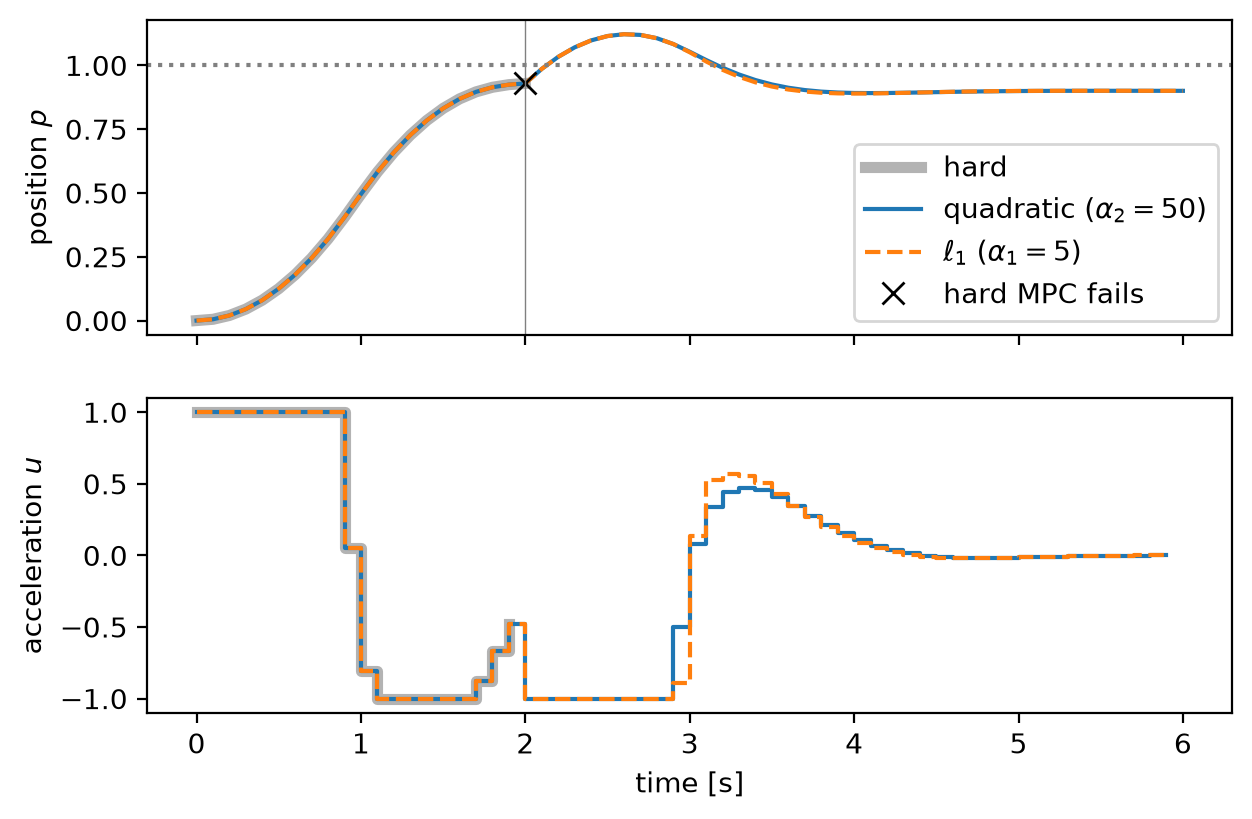

In [5]:
# Controllers
hard = controller()  # vanilla OSQP
quadratic = controller(PT.OSQP_PENALTY_L1L2, alpha2=50.0)
l1 = controller(PT.OSQP_PENALTY_L1L2, alpha1=5.0)

# Closed-loop simulations
x_hard, u_hard = simulate(hard)
x_quadratic, u_quadratic = simulate(quadratic)
x_l1, u_l1 = simulate(l1)

# Plot
fig, (ax_p, ax_u) = plt.subplots(2, 1, figsize=(7, 4.5), sharex=True)

ax_p.plot(np.arange(len(x_hard)) * dt, x_hard[:, 0], color="0.7", linewidth=4, label="hard")
ax_p.plot(np.arange(len(x_quadratic)) * dt, x_quadratic[:, 0], color="C0", label=r"quadratic ($\alpha_2 = 50$)")
ax_p.plot(np.arange(len(x_l1)) * dt, x_l1[:, 0], color="C1", linestyle="--", label=r"$\ell_1$ ($\alpha_1 = 5$)")
ax_p.plot((len(x_hard) - 1) * dt, x_hard[-1, 0], "kx", markersize=8, label="hard MPC fails")
ax_p.axhline(p_max, color="gray", linestyle=":")
ax_p.axvline(2.0, color="gray", linewidth=0.5)
ax_p.set_ylabel("position $p$")
ax_p.legend()

ax_u.step(np.arange(len(u_hard)) * dt, u_hard, where="post", color="0.7", linewidth=4)
ax_u.step(np.arange(len(u_quadratic)) * dt, u_quadratic, where="post", color="C0")
ax_u.step(np.arange(len(u_l1)) * dt, u_l1, where="post", color="C1", linestyle="--")
ax_u.set_ylabel("acceleration $u$")
ax_u.set_xlabel("time [s]")
plt.show()

### 2. The penalty shapes the violation

Now the reference $p_\mathrm{ref} = 1.1$ is beyond the limit, and there is no disturbance.

- **Quadratic:** small violations are cheap, so the cart settles slightly above the limit.
- **$\ell_1$:** an exact penalty. If $\alpha_1$ exceeds the Lagrange multiplier, the limit holds exactly.

`solver.slack(z)` returns the slack $\xi$ of every row.

quadratic: final position 1.0167, largest slack 1.7e-02
l1:        final position 1.0000, largest slack 2.4e-06


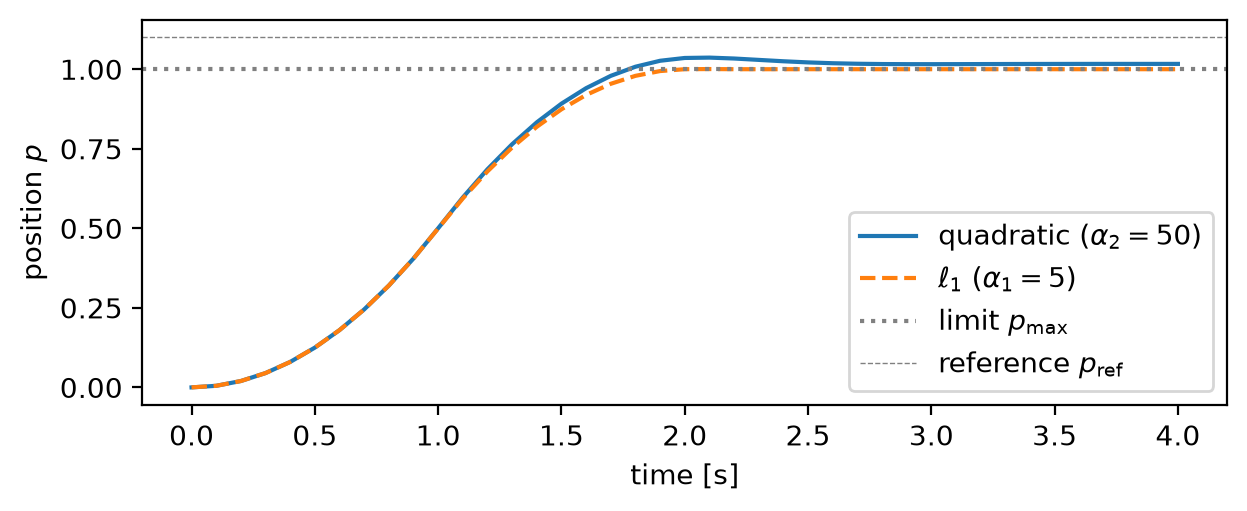

In [6]:
# Controllers
quadratic = controller(PT.OSQP_PENALTY_L1L2, alpha2=50.0, p_ref=1.1)
l1 = controller(PT.OSQP_PENALTY_L1L2, alpha1=5.0, p_ref=1.1)

# Closed-loop simulations, without disturbance
x_quadratic, _ = simulate(quadratic, steps=40, kick=0.0)
x_l1, _ = simulate(l1, steps=40, kick=0.0)

# Predicted slack of the position constraints
xi_quadratic = quadratic.slack(quadratic.solve().x)[pos_rows]
xi_l1 = l1.slack(l1.solve().x)[pos_rows]
print(f"quadratic: final position {x_quadratic[-1, 0]:.4f}, largest slack {np.abs(xi_quadratic).max():.1e}")
print(f"l1:        final position {x_l1[-1, 0]:.4f}, largest slack {np.abs(xi_l1).max():.1e}")

# Plot
t = np.arange(41) * dt
plt.figure(figsize=(7, 2.5))
plt.plot(t, x_quadratic[:, 0], color="C0", label=r"quadratic ($\alpha_2 = 50$)")
plt.plot(t, x_l1[:, 0], color="C1", linestyle="--", label=r"$\ell_1$ ($\alpha_1 = 5$)")
plt.axhline(p_max, color="gray", linestyle=":", label=r"limit $p_{\max}$")
plt.axhline(1.1, color="gray", linestyle="--", linewidth=0.5, label=r"reference $p_\mathrm{ref}$")
plt.xlabel("time [s]")
plt.ylabel("position $p$")
plt.legend()
plt.show()

### 3. Updating the penalty online

`update_penalty_params` changes the weights without a new setup (`update_penalty_types` changes the types). With $\alpha_1$ below the multiplier, the cart moves past the limit.

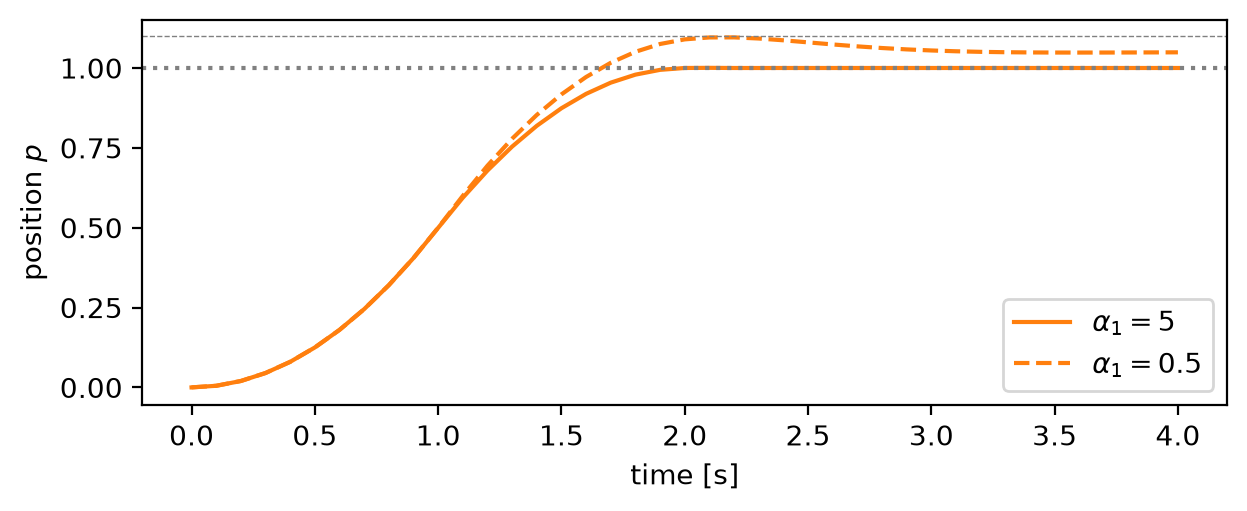

In [7]:
solver = controller(PT.OSQP_PENALTY_L1L2, alpha1=5.0, p_ref=1.1)
x_strict, _ = simulate(solver, steps=40, kick=0.0)

# Lower the l1 weight (scalar or per-row array)
solver.update_penalty_params(alpha1=0.5)
x_relaxed, _ = simulate(solver, steps=40, kick=0.0)

t = np.arange(41) * dt
plt.figure(figsize=(7, 2.5))
plt.plot(t, x_strict[:, 0], "C1-", label=r"$\alpha_1 = 5$")
plt.plot(t, x_relaxed[:, 0], "C1--", label=r"$\alpha_1 = 0.5$")
plt.axhline(p_max, color="gray", linestyle=":")
plt.axhline(1.1, color="gray", linestyle="--", linewidth=0.5)
plt.xlabel("time [s]")
plt.ylabel("position $p$")
plt.legend()
plt.show()